# Exploratory Data Analysis (EDA) for Twitter Bot Account Prediction

Explore the training data to understand the features, target distribution, and any patterns that may help in predicting bot accounts.

By Winston Ho A0272095B

### Imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

### Load data

In [3]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
sample_submission = pd.read_csv('data/sample_submission.csv')

# Display the first few rows of each DataFrame
display(train.head())
display(test.head())
display(sample_submission.head())

,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,lang,location,profile_background_image_url,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days,target
0,2012-01-15 23:40:09,True,False,Cosplayer/Fitness lover. Come to me https://t....,74,7,0,False,465096524,en,unknown,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/9666745212...,reml5477,20,False,0.006,3138,1
1,2016-10-04 00:44:39,False,False,pobody’s nerfect,50443,164,590,True,783105517673648132,cy,she/her,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/1281752126...,kinlibra,6469,False,4.572,1415,0
2,2009-05-23 04:04:13,False,False,gracias por participar 🏅,9394,208,189,False,41970759,es,La diaspora,http://abs.twimg.com/images/themes/theme17/bg.gif,http://pbs.twimg.com/profile_images/1233811596...,_delaualau,30296,False,7.378,4106,0
3,2009-05-17 04:31:31,False,False,Stand Up Comedian/Actor from North Philadelphi...,46,66180,1090,True,40607946,en,"Calabasas, CA",http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/1184851104...,SpankHorton,164957,False,40.116,4112,0
4,2009-02-16 13:11:21,True,False,Assignment Editor at NBC10 and President of Ja...,1223,487,867,True,20983433,en,"Jenkintown, PA",http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/5234863934...,javelinjt,1752,False,0.417,4201,0


,index,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,lang,location,profile_background_image_url,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days
0,0,2007-03-27 22:56:04,False,False,Dad. #ADHD @fasternormal Pod host. Author/keyn...,22290,163813,1746,True,2569261,en,"New York, NY",http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/1186468889...,petershankman,42013,True,8.586,4893
1,1,2013-03-30 08:47:01,True,False,NaN,685,44,637,False,1316038452,NaN,unknown,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/9637876928...,Mihail_HD,111,False,0.041,2699
2,2,2009-04-25 15:24:08,False,False,#UGAMOM #GODAWGS,12257,276,194,True,35233977,de,"Augusta, GA",http://abs.twimg.com/images/themes/theme3/bg.gif,http://pbs.twimg.com/profile_images/1246470377...,TinkerMazell,18142,False,4.390,4133
3,3,2010-08-06 22:21:56,True,False,"golfer, traveler, car guy, PCA member, owns 19...",30806,1124,4999,True,175542625,en,New York,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/1391357162...,joecangolfICC,20624,False,5.627,3665
4,4,2015-03-02 12:29:39,True,False,Do you like it gently? Come in! 💚💚💚 https://t....,224,22,265,False,3056068536,en,unknown,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/9680856906...,TiesiogDovydas,64,False,0.032,1996


,index,target
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


In [5]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11232 entries, 0 to 11231
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   index                         11232 non-null  int64  
 1   created_at                    11232 non-null  object 
 2   default_profile               11232 non-null  bool   
 3   default_profile_image         11232 non-null  bool   
 4   description                   9066 non-null   object 
 5   favourites_count              11232 non-null  int64  
 6   followers_count               11232 non-null  int64  
 7   friends_count                 11232 non-null  int64  
 8   geo_enabled                   11232 non-null  bool   
 9   id                            11232 non-null  int64  
 10  lang                          8863 non-null   object 
 11  location                      11230 non-null  object 
 12  profile_background_image_url  9968 non-null   object 
 13  p

In [6]:
print(test.isnull().sum())

index                              0
created_at                         0
default_profile                    0
default_profile_image              0
description                     2166
favourites_count                   0
followers_count                    0
friends_count                      0
geo_enabled                        0
id                                 0
lang                            2369
location                           2
profile_background_image_url    1264
profile_image_url                  0
screen_name                        0
statuses_count                     0
verified                           0
average_tweets_per_day             0
account_age_days                   0
dtype: int64


In [4]:
# Basic info about the train dataset
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26206 entries, 0 to 26205
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   created_at                    26206 non-null  object 
 1   default_profile               26206 non-null  bool   
 2   default_profile_image         26206 non-null  bool   
 3   description                   21115 non-null  object 
 4   favourites_count              26206 non-null  int64  
 5   followers_count               26206 non-null  int64  
 6   friends_count                 26206 non-null  int64  
 7   geo_enabled                   26206 non-null  bool   
 8   id                            26206 non-null  int64  
 9   lang                          20618 non-null  object 
 10  location                      26204 non-null  object 
 11  profile_background_image_url  22971 non-null  object 
 12  profile_image_url             26205 non-null  object 
 13  s

In [23]:
# Check for missing values
print("\nMissing values per column:")
print(train.isnull().sum())


Missing values per column:
created_at                         0
default_profile                    0
default_profile_image              0
description                     5091
favourites_count                   0
followers_count                    0
friends_count                      0
geo_enabled                        0
id                                 0
lang                            5588
location                           2
profile_background_image_url    3235
profile_image_url                  1
screen_name                        0
statuses_count                     0
verified                           0
average_tweets_per_day             0
account_age_days                   0
target                             0
dtype: int64


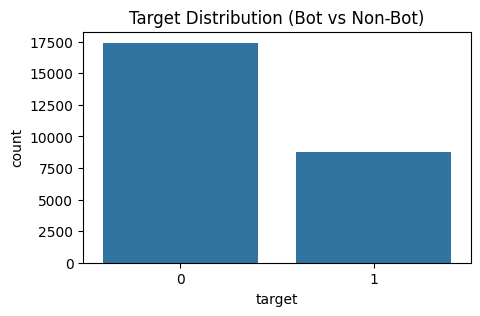

Target distribution:
 target
0    0.664848
1    0.335152
Name: proportion, dtype: float64


In [24]:
# Plot target distribution
plt.figure(figsize=(5,3))
sns.countplot(x='target', data=train)
plt.title('Target Distribution (Bot vs Non-Bot)')
plt.show()
print("Target distribution:\n", train['target'].value_counts(normalize=True))

In [25]:
# Descriptive statistics for numeric columns
print("Numeric features:")
display(train.describe())

# Descriptive statistics for categorical columns
print("Categorical features:")
display(train.describe(include=['object']))

# Descriptive statistics for boolean features
print("Boolean features:")
bool_cols = train.select_dtypes(include=['bool', 'int']).columns
# Exclude target and numeric columns that are not boolean
bool_cols = [col for col in bool_cols if train[col].dropna().isin([0,1]).all() and col != 'target']
display(train[bool_cols].describe())

Numeric features:


,favourites_count,followers_count,friends_count,id,statuses_count,average_tweets_per_day,account_age_days,target
count,26206.000000,2.620600e+04,2.620600e+04,2.620600e+04,2.620600e+04,26206.000000,26206.000000,26206.000000
mean,12159.971342,3.732983e+05,4.427275e+03,1.253306e+17,2.072485e+04,6.754636,3017.870831,0.335152
std,33628.948536,2.515996e+06,4.602204e+04,3.035728e+17,6.345569e+04,22.782745,1018.958572,0.472053
min,0.000000,0.000000e+00,0.000000e+00,5.860000e+02,0.000000e+00,0.000000,483.000000,0.000000
25%,347.000000,3.400000e+01,3.400000e+01,9.799366e+07,1.331000e+03,0.486250,2302.000000,0.000000
50%,2037.000000,3.540000e+02,2.920000e+02,3.997210e+08,4.143500e+03,1.464000,3218.000000,0.000000
75%,8751.750000,8.241500e+03,8.780000e+02,2.480241e+09,1.679150e+04,5.460000,3895.000000,1.000000
max,839929.000000,1.216415e+08,1.641962e+06,1.120974e+18,2.771910e+06,1191.286000,5151.000000,1.000000


Categorical features:


,created_at,description,lang,location,profile_background_image_url,profile_image_url,screen_name
count,26206,21115,20618,26204,22971,26205,26206
unique,26205,20988,48,8884,20,25820,26206
top,2009-04-18 00:49:34,Actor,en,unknown,http://abs.twimg.com/images/themes/theme1/bg.png,http://abs.twimg.com/sticky/default_profile_im...,reml5477
freq,2,10,14980,9207,15171,386,1


Boolean features:


,default_profile,default_profile_image,geo_enabled,verified
count,26206,26206,26206,26206
unique,2,2,2,2
top,False,False,False,False
freq,15169,25820,14384,20907


Below are a list of all features:

<ol>
<li><b>created_at</b> - The date and time when the Twitter account was created.</li>
<li><b>default_profile</b> - Indicates whether the user has a default profile settings.</li>
<li><b>default_profile_image</b> - Indicates whether the user has a default profile image.</li>
<li><b>description</b> - The user's profile description or bio.</li>
<li><b>favourites_count</b> - The number of tweets the user has liked.</li>
<li><b>followers_count</b> - The number of followers the user has.</li>
<li><b>friends_count</b> - The number of accounts the user is following.</li>
<li><b>geo_enabled</b> - Indicates whether the user has enabled location services.</li>
<li><b>id</b> - The unique identifier for the Twitter account.</li>
<li><b>lang</b> - The language preference set for the account.</li>
<li><b>location</b> - The location information provided by the user.</li>
<li><b>profile_background_image_url</b> - URL of the user's profile background image.</li>
<li><b>profile_image_url</b> - URL of the user's profile image.</li>
<li><b>screen_name</b> - The user's Twitter handle or username.</li>
<li><b>statuses_count</b> - The total number of tweets posted by the user.</li>
<li><b>verified</b> - Indicates whether the account is verified by Twitter.</li>
<li><b>average_tweets_per_day</b> - The average number of tweets posted per day.</li>
<li><b>account_age_days</b> - The age of the account in days.</li>
<li><b>target</b> - The classification label indicating whether the account is a bot or not. 1 means it is a bot.</li>
</ol>

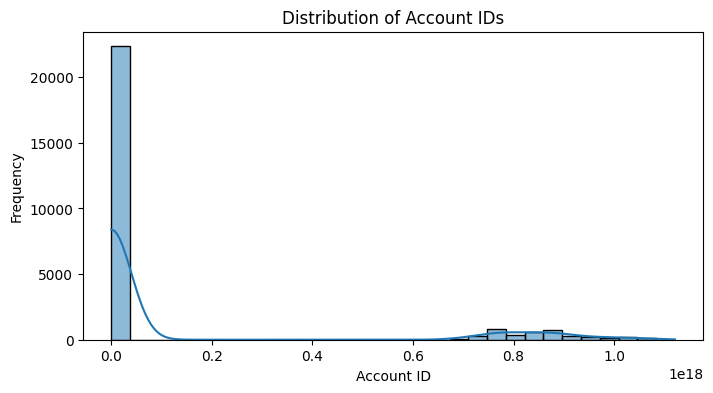

In [26]:
plt.figure(figsize=(8, 4))
sns.histplot(train['id'], bins=30, kde=True)
plt.title('Distribution of Account IDs')
plt.xlabel('Account ID')
plt.ylabel('Frequency')
plt.show()

In [27]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# =========================
# Correlation check
# =========================
# Focus on 'id' vs 'account_age_days' correlation
corr = train[['id', 'account_age_days']].corr()
print("Correlation between ID and account_age_days:\n", corr, "\n")

# =========================
# Feature importance check
# =========================
# Prepare features and target
# Drop 'created_at', 'description', 'lang', 'location', 'profile_background_image_url', 
# 'profile_image_url', 'screen_name' for simplicity, keep numeric/binary features
features = [
    'id', 'default_profile', 'default_profile_image', 'favourites_count', 
    'followers_count', 'friends_count', 'geo_enabled', 'verified', 
    'average_tweets_per_day', 'account_age_days', 'statuses_count'
]
X = train[features]
y = train['target']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Feature importance
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance

Correlation between ID and account_age_days:
                         id  account_age_days
id                1.000000         -0.736162
account_age_days -0.736162          1.000000 



followers_count           0.205102
favourites_count          0.185256
friends_count             0.140235
statuses_count            0.119484
average_tweets_per_day    0.101144
account_age_days          0.086888
id                        0.083265
verified                  0.034461
geo_enabled               0.027329
default_profile           0.014961
default_profile_image     0.001875
dtype: float64

1. **Correlation**

The correlation between `id` and `account_age_days` is:

```
id vs account_age_days: -0.736
```

- There is a strong negative correlation, which is expected because Twitter IDs increase over time, while `account_age_days` decreases as the account gets older.
- This confirms high collinearity, so keeping both features in the model is unnecessary.

2. **Feature Importance**

From the Random Forest classifier, the feature importance values are:

```
account_age_days: 0.0869
id: 0.0833
```

- Both `id` and `account_age_days` have relatively low importance compared to features like `followers_count`, `favourites_count`, `friends_count`, and `statuses_count`.
- The small importance of `id` is largely redundant with `account_age_days` and does not provide unique predictive signal.

**Conclusion**
- The `id` column can be dropped from the model because it is redundant and collinear with `account_age_days`.
- Keep `account_age_days` as it provides meaningful temporal information in numeric form.
- Other numeric features such as `followers_count`, `friends_count`, `statuses_count`, etc., are more informative for prediction and should be retained.


### Numerical Features

Numerical attributes include the following:

<ol>
<li>favourites_count</li>
<li>followers_count</li>
<li>friends_count</li>
<li>statuses_count</li>
<li>average_tweets_per_day</li>
<li>account_age_days</li>
</ol> 

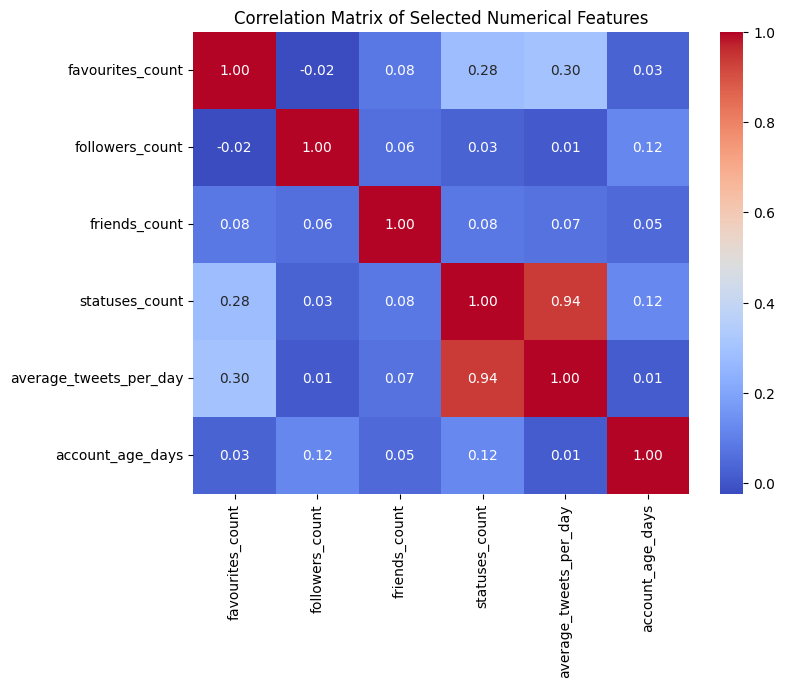

In [29]:
# Define selected numerical features (excluding 'target')
numeric_cols = [
	'favourites_count', 'followers_count', 'friends_count',
	'statuses_count', 'average_tweets_per_day', 'account_age_days'
]

# Correlation matrix for selected numerical features
corr_matrix = train[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Selected Numerical Features')
plt.show()


We find that `statuses_count` and `average_tweets_per_day` are highly correlated. `statuses_count` is essentially `average_tweets_per_day` * `account_age_days`, therefore we can consider dropping statuses count to avoid multicollinearity.

*Note that since the three features rank quite highly on feature importance in the basic model above, we should still keep all three for now, the model might not be able to derive the relationship between the three features which explain the time, volume and rate dimensions of tweeting activity*

The rest of the features do not have significantly high correlation that might disrupt our model.

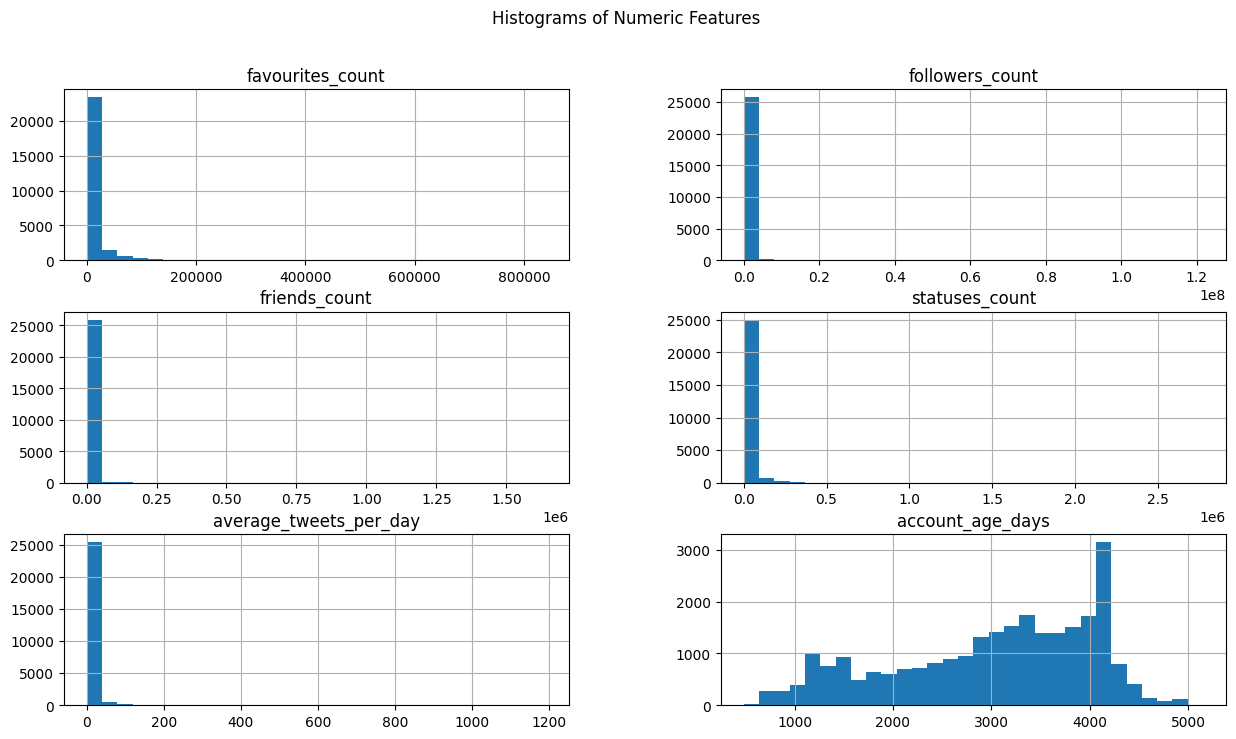

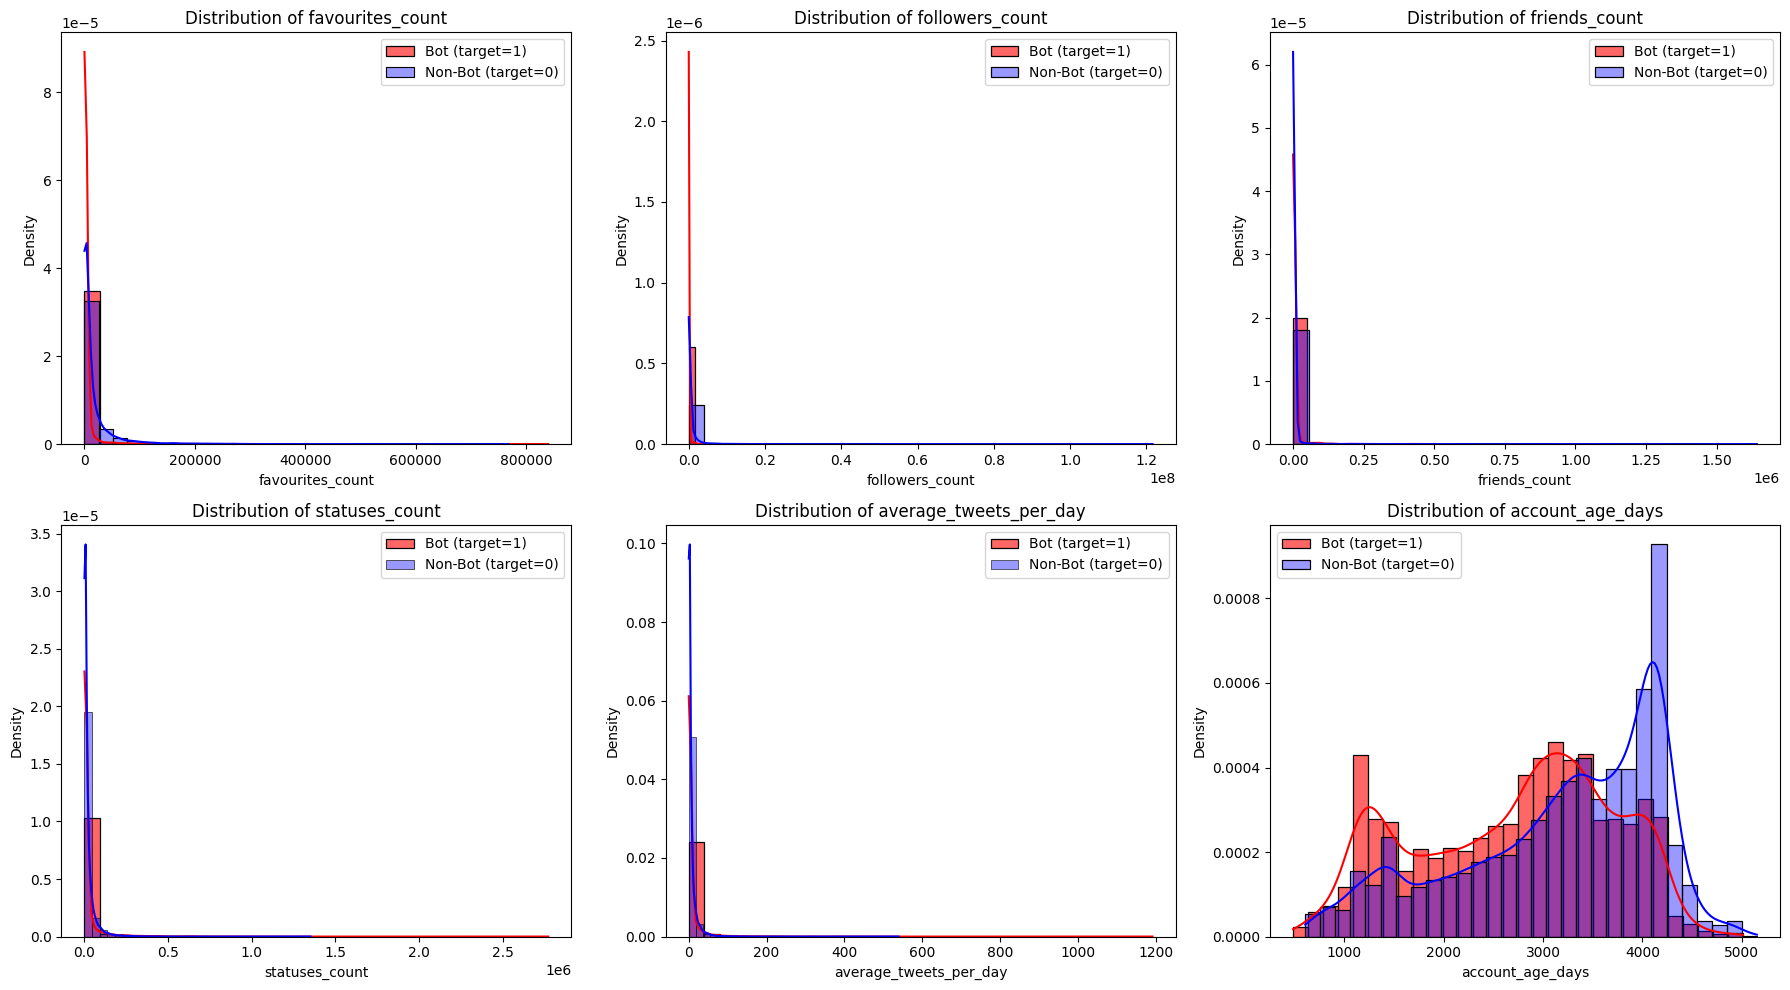

In [37]:
# Plot histograms for numeric features
train[numeric_cols].hist(figsize=(15, 8), bins=30)
plt.suptitle('Histograms of Numeric Features')
# Overlap distributions of target=1 for each feature
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, col in enumerate(numeric_cols):
    ax = axes[i // 3, i % 3]
    sns.histplot(train[train['target'] == 1][col], bins=30, color='red', label='Bot (target=1)', kde=True, stat='density', ax=ax, alpha=0.6)
    sns.histplot(train[train['target'] == 0][col], bins=30, color='blue', label='Non-Bot (target=0)', kde=True, stat='density', ax=ax, alpha=0.4)
    ax.set_title(f'Distribution of {col}')
    ax.legend()
plt.tight_layout()
plt.show()

A lot of these features are right skewed, lets log transform them all except `account_age_days`.

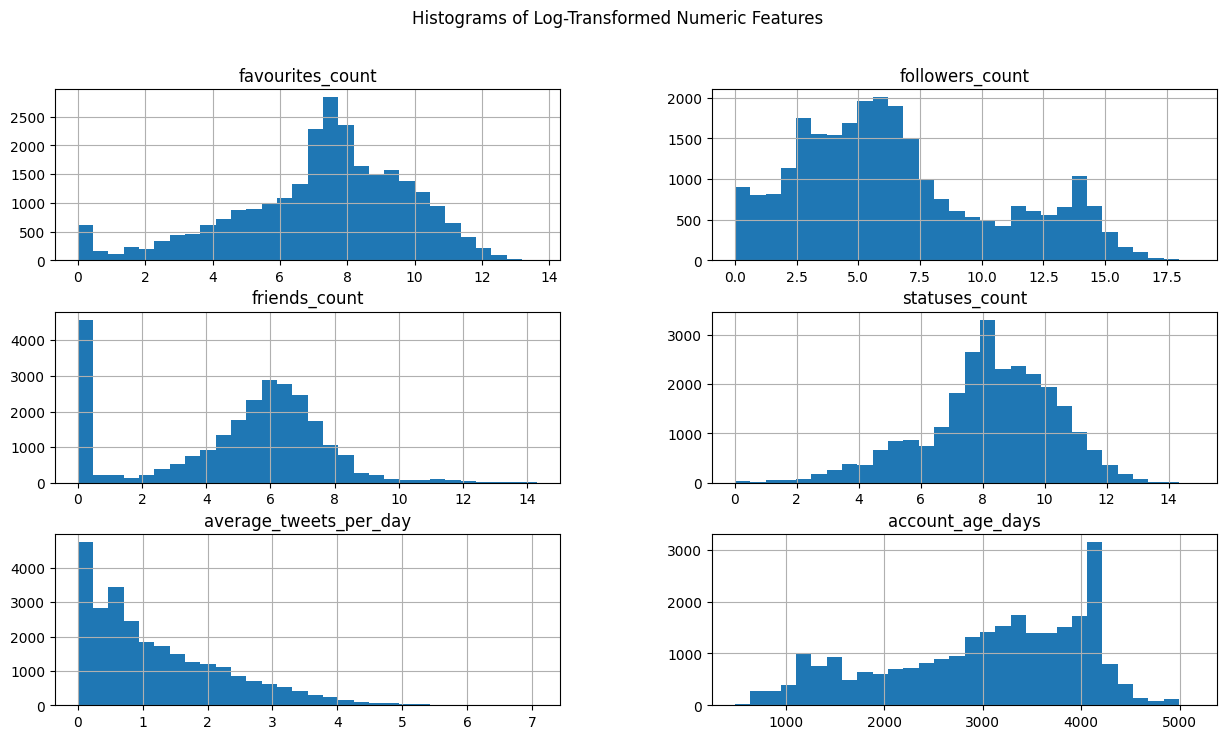

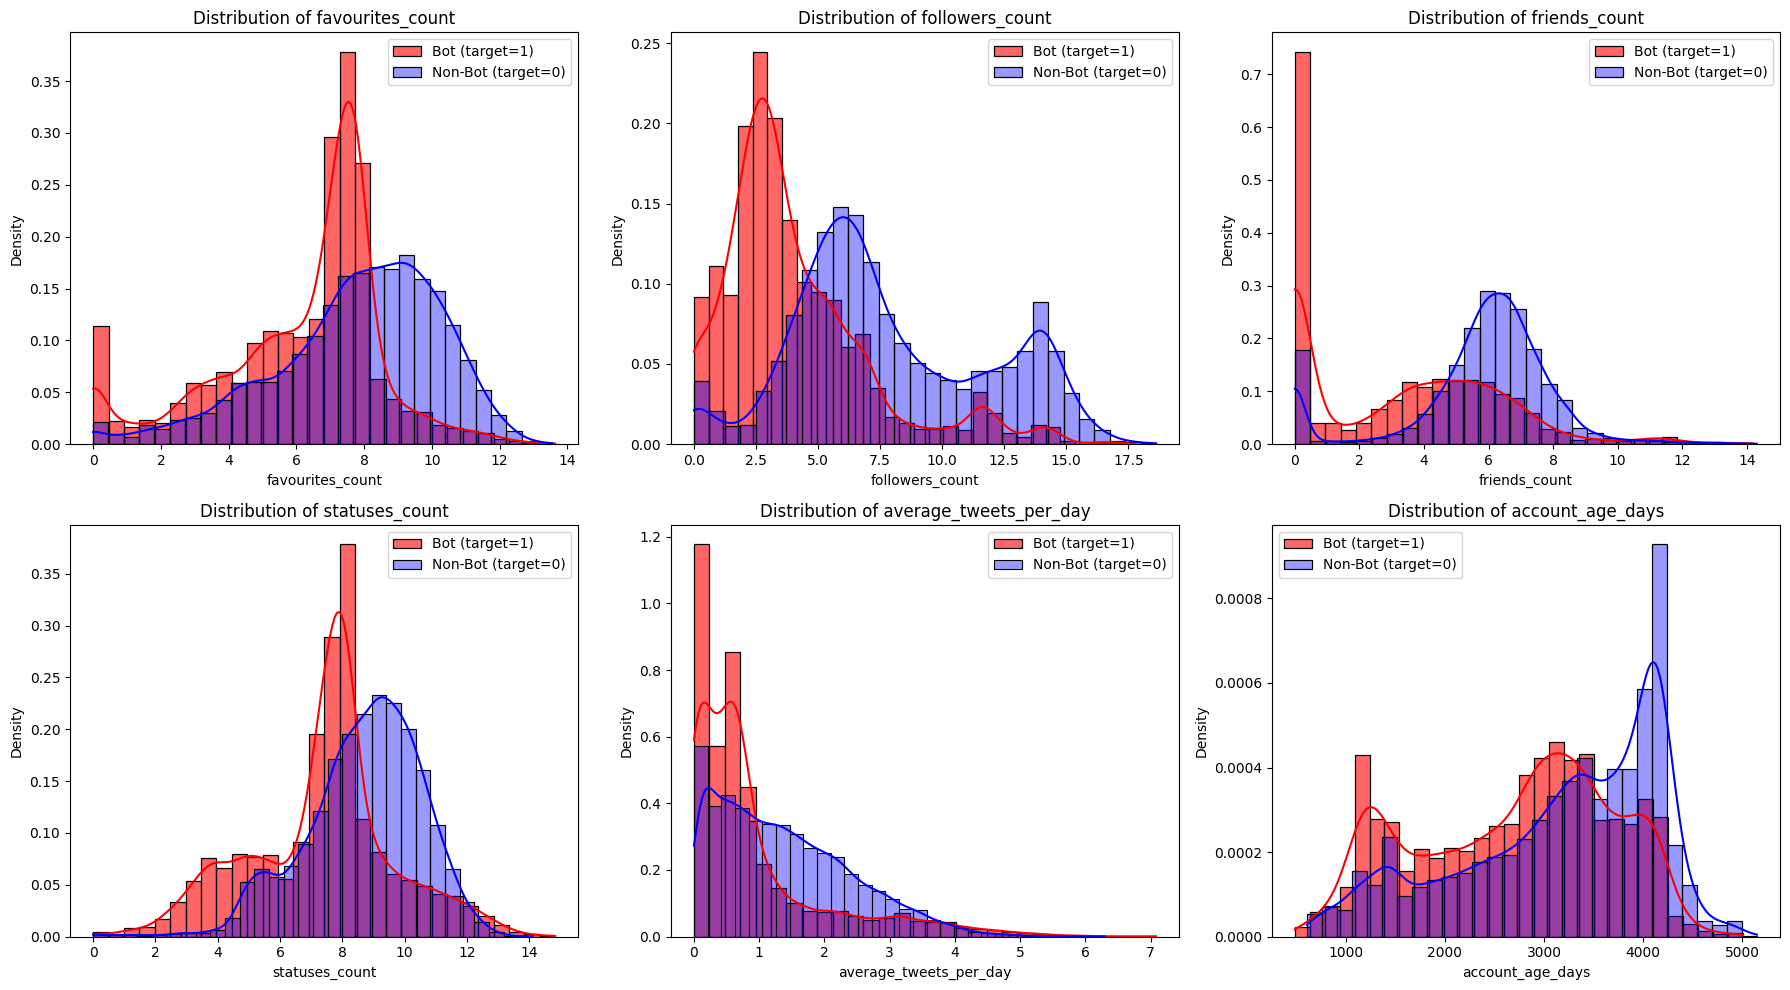

In [36]:
# Log transform all numeric columns except 'account_age_days'
log_cols = [
	'favourites_count', 'followers_count', 'friends_count',
	'statuses_count', 'average_tweets_per_day'
]
train_log = train.copy()
for col in log_cols:
    train_log[col] = train_log[col].apply(lambda x: np.log1p(x))

# Plot histograms for log-transformed numeric features
train_log[log_cols + ['account_age_days']].hist(figsize=(15, 8), bins=30)
plt.suptitle('Histograms of Log-Transformed Numeric Features')
# Overlap distributions of target=1 for each feature
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, col in enumerate(log_cols + ['account_age_days']):
    ax = axes[i // 3, i % 3]
    sns.histplot(train_log[train['target'] == 1][col], bins=30, color='red', label='Bot (target=1)', kde=True, stat='density', ax=ax, alpha=0.6)
    sns.histplot(train_log[train['target'] == 0][col], bins=30, color='blue', label='Non-Bot (target=0)', kde=True, stat='density', ax=ax, alpha=0.4)
    ax.set_title(f'Distribution of {col}')
    ax.legend()
plt.tight_layout()
plt.show()

Now that we are done with transformations, Q-Q plot against normal distribution to confirm outliers have been handled.

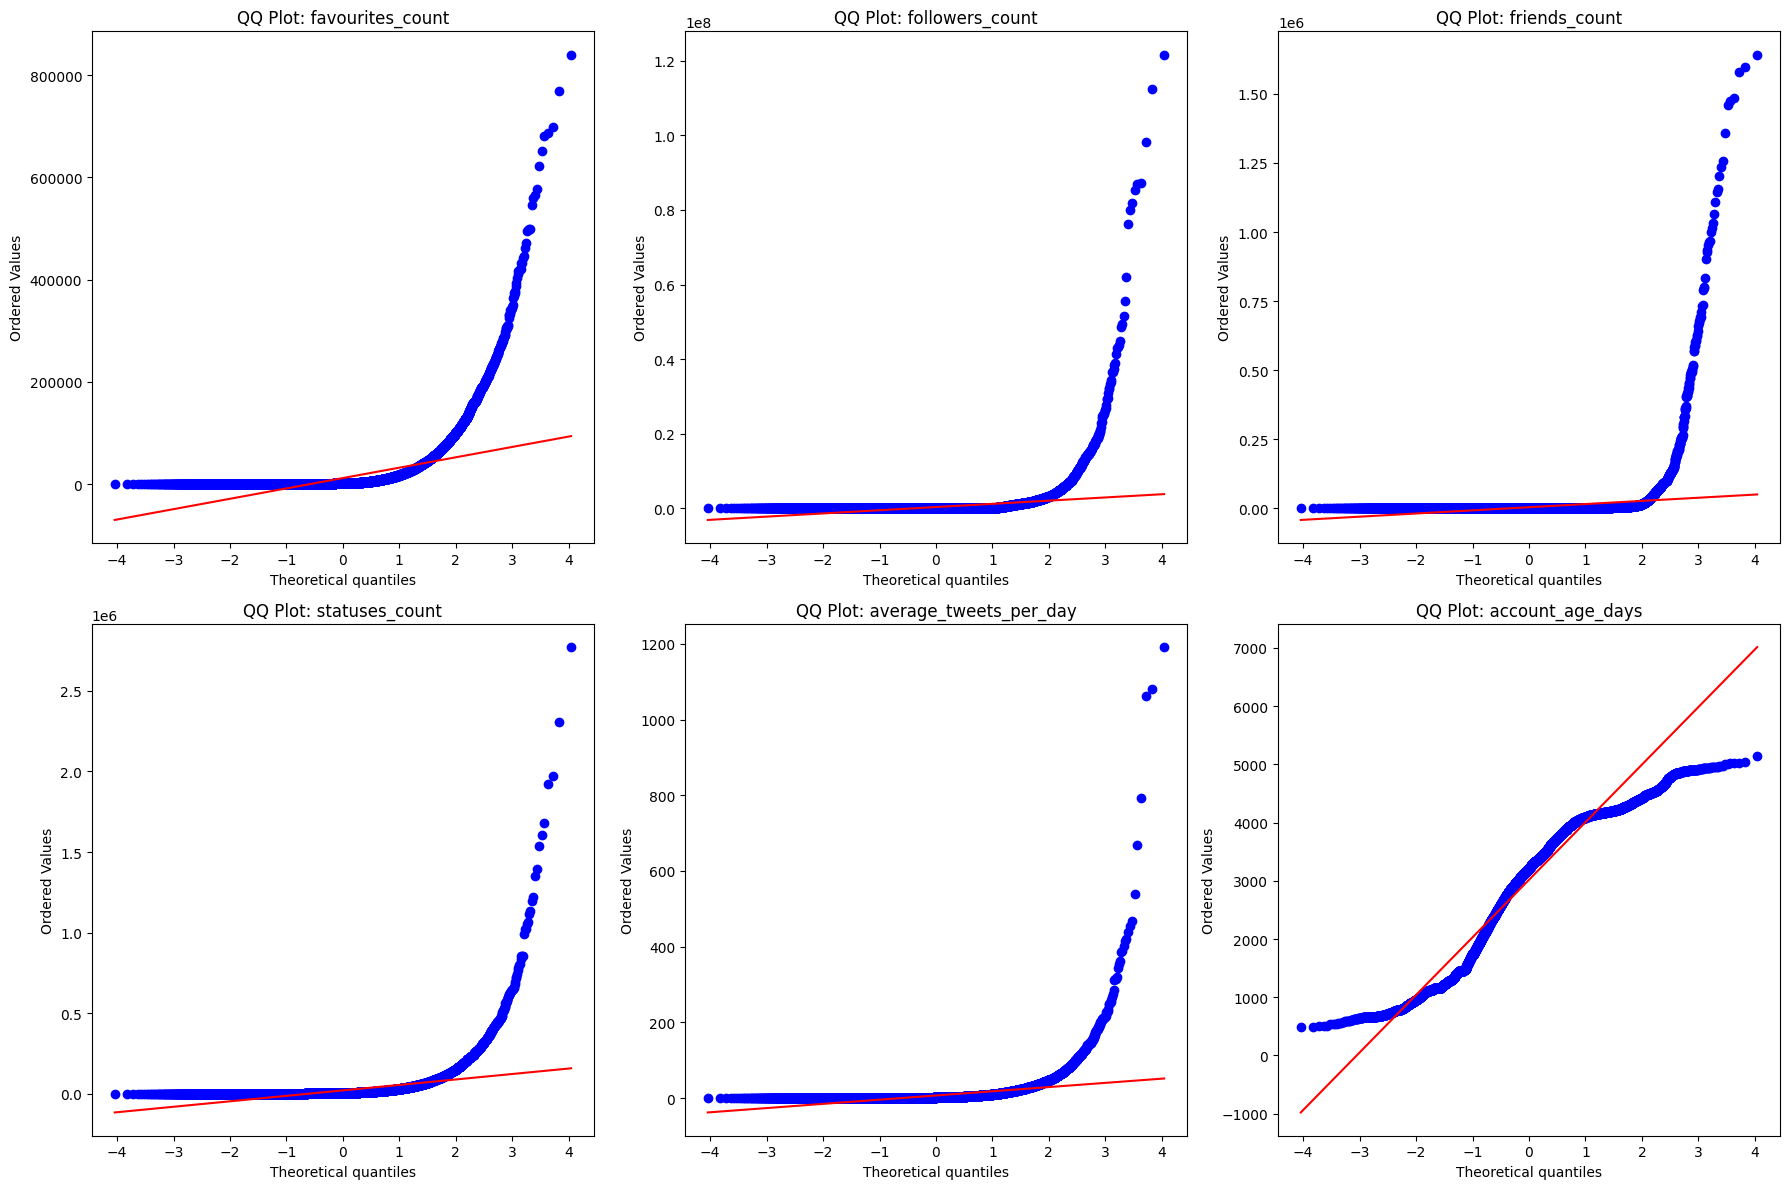

In [34]:
import scipy.stats as stats

plt.figure(figsize=(18, 12))
for i, col in enumerate(numeric_cols):
    plt.subplot(2, 3, i+1)
    stats.probplot(train[col].dropna(), dist="norm", plot=plt)
    plt.title(f'QQ Plot: {col}')
plt.tight_layout()
plt.show()

### Binary Features

Binary attributes include the following:

*Note: remove target as it is not a feature*

<ol>
<li>default_profile</li>
<li>default_profile_image</li>
<li>geo_enabled</li>
<li>verified</li>
</ol> 

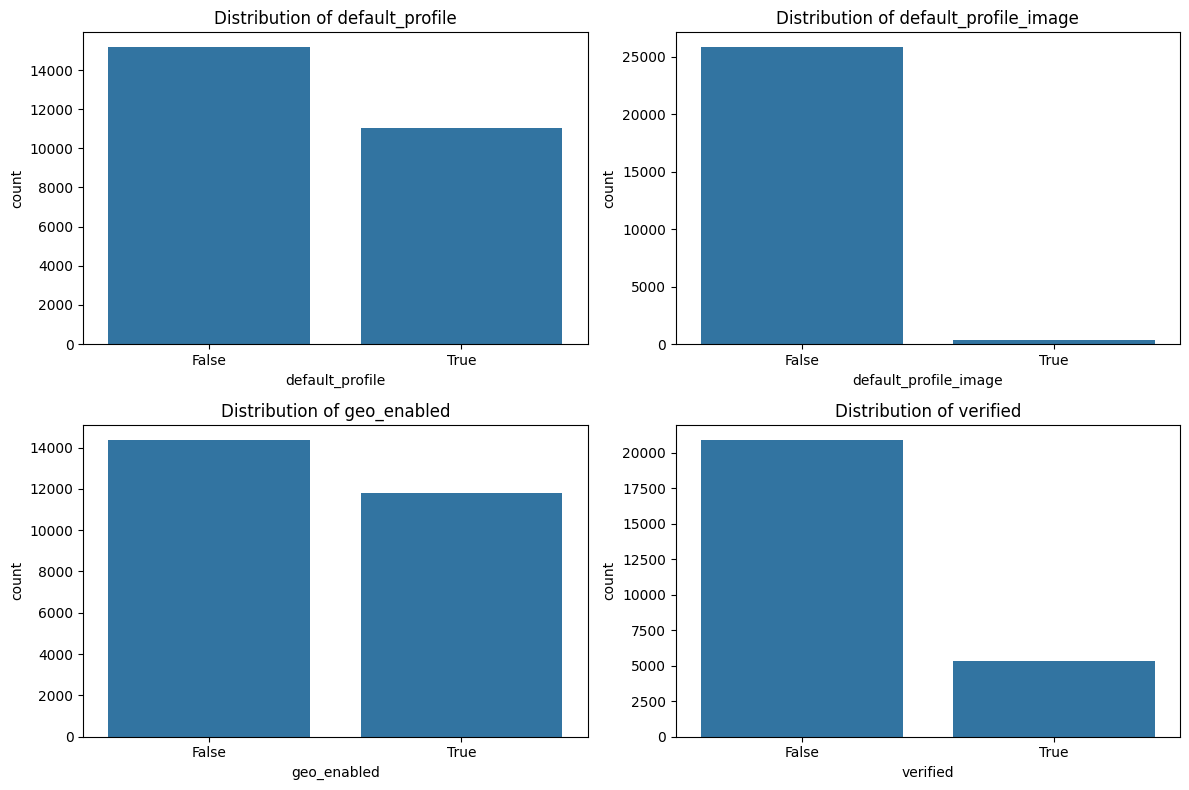

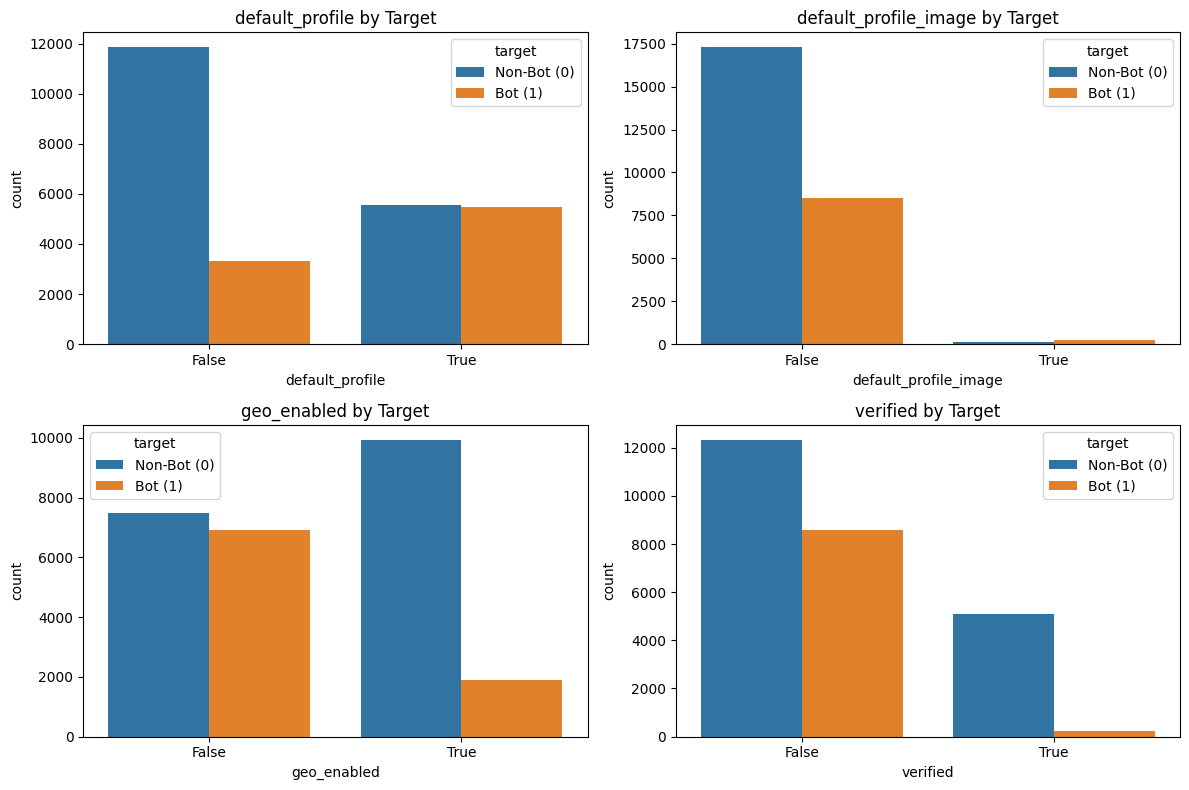

In [39]:
binary_features = ['default_profile', 'default_profile_image', 'geo_enabled', 'verified']

# Plot binary feature distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(binary_features):
    ax = axes[i // 2, i % 2]
    sns.countplot(x=col, data=train, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# Plot binary features split by target
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(binary_features):
    ax = axes[i // 2, i % 2]
    sns.countplot(x=col, hue='target', data=train, ax=ax)
    ax.set_title(f'{col} by Target')
    ax.legend(title='target', labels=['Non-Bot (0)', 'Bot (1)'])
plt.tight_layout()
plt.show()

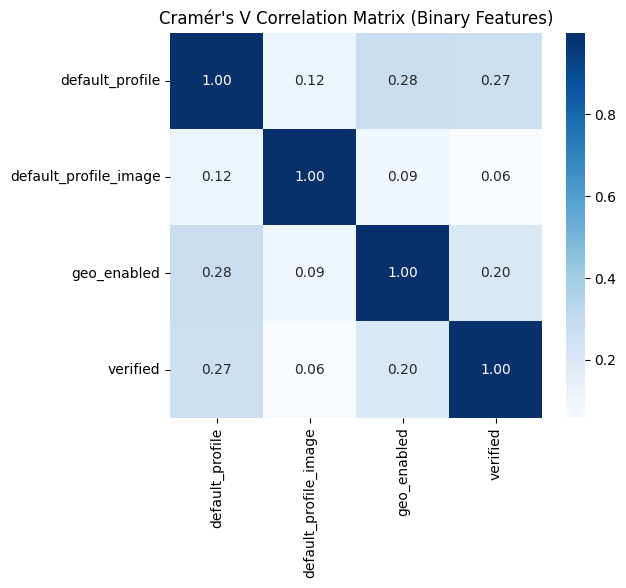

In [41]:
from scipy.stats import chi2_contingency

def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k - 1, r - 1))

cramers_matrix = pd.DataFrame(index=binary_features, columns=binary_features, dtype=float)

for col1 in binary_features:
    for col2 in binary_features:
        confusion = pd.crosstab(train[col1], train[col2])
        # Ensure confusion is a numpy array for cramers_v
        cramers_matrix.at[col1, col2] = cramers_v(confusion.values)

plt.figure(figsize=(6, 5))
sns.heatmap(cramers_matrix.astype(float), annot=True, cmap='Blues', fmt='.2f')
plt.title("Cramér's V Correlation Matrix (Binary Features)")
plt.show()

### Other Features

Other attributes include the following:

**Datetime:**
<ol>
<li>created_at</li>
</ol> 

**Categorical:**
<ol>
<li>location</li>
</ol> 

**Text and Other:**
<ol>
<li>lang</li>
<li>description</li>
<li>profile_background_image_url</li>
<li>profile_image_url</li>
<li>screen_name</li>
</ol> 

### Datetime

--- Analysis of 'created_at' attribute ---

Descriptive statistics for 'created_at':
count                            26206
mean     2012-05-15 01:14:27.945356032
min                2006-07-13 09:05:49
25%                2009-12-19 22:26:21
50%         2011-10-27 23:00:51.500000
75%      2014-04-30 17:59:38.249999872
max                2019-04-24 08:53:21
Name: created_at, dtype: object

Earliest account creation date: 2006-07-13 09:05:49
Latest account creation date: 2019-04-24 08:53:21
Total time span of account creation dates: 4667 days 23:47:32


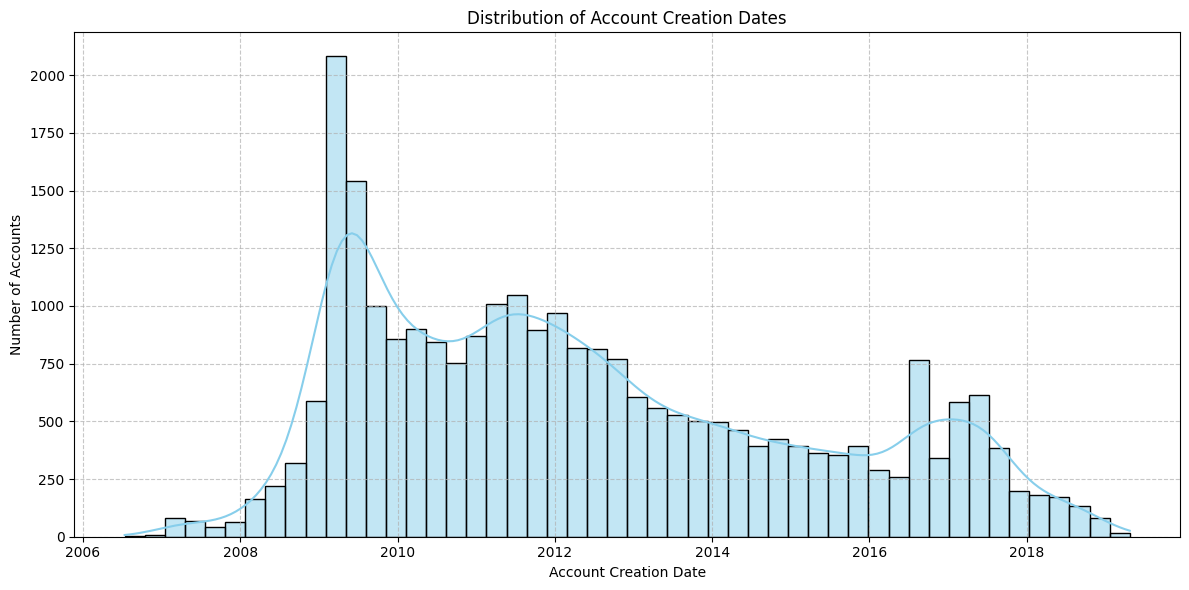

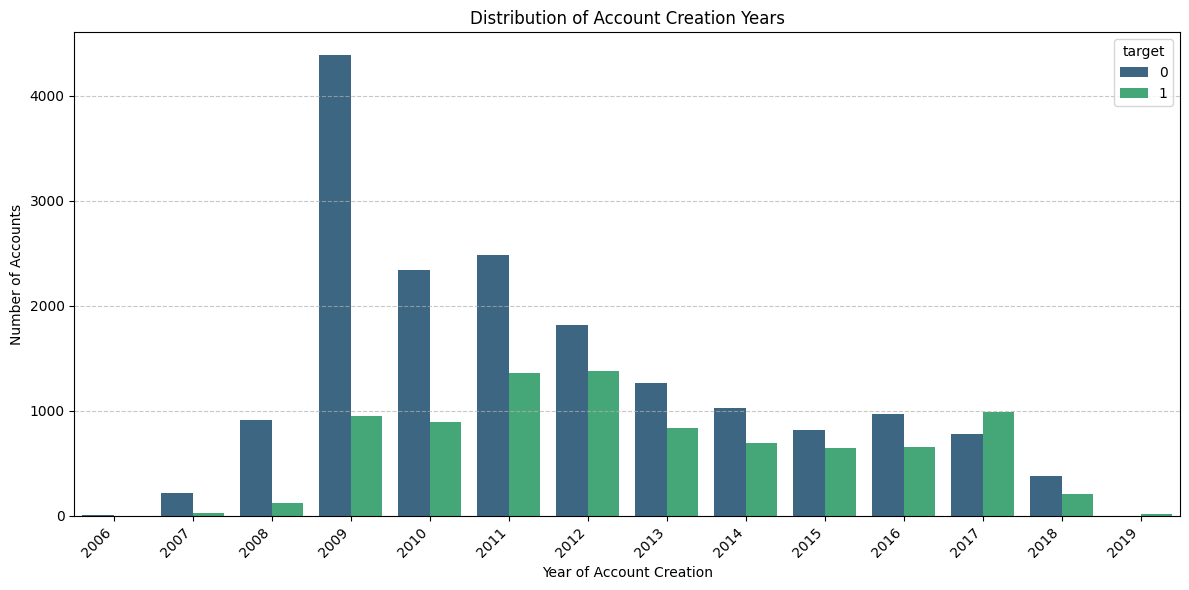

In [14]:
# Ensure 'created_at' is a datetime object
if not pd.api.types.is_datetime64_any_dtype(train['created_at']):
    train['created_at'] = pd.to_datetime(train['created_at'])

print("--- Analysis of 'created_at' attribute ---")

# Display descriptive statistics for 'created_at'
print("\nDescriptive statistics for 'created_at':")
print(train['created_at'].describe())

# Calculate and print additional useful statistics
min_date = train['created_at'].min()
max_date = train['created_at'].max()
time_span = max_date - min_date
print(f"\nEarliest account creation date: {min_date}")
print(f"Latest account creation date: {max_date}")
print(f"Total time span of account creation dates: {time_span}")

# Visualize the distribution of account creation dates
plt.figure(figsize=(12, 6))
sns.histplot(train['created_at'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Account Creation Dates')
plt.xlabel('Account Creation Date')
plt.ylabel('Number of Accounts')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Visualize the distribution of account creation years for clearer trends
plt.figure(figsize=(12, 6))
sns.countplot(x=train['created_at'].dt.year, palette='viridis', hue=train['target'])
plt.title('Distribution of Account Creation Years')
plt.xlabel('Year of Account Creation')
plt.ylabel('Number of Accounts')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Just visualize the creation date but no additional info from acc age days so drop.

### Categorical

--- Analysis of 'lang' ---
Number of unique languages: 48

Value counts for 'lang':
lang
en       14980
es         845
pt         478
it         455
ar         420
de         390
fr         277
ja         259
af         236
id         205
ru         177
tr         156
tl         139
sw         133
ca         126
da         118
no         114
cy         111
nl         110
ro         105
sv          92
so          88
ko          77
et          71
zh-cn       67
fi          52
pl          41
vi          38
hr          34
sl          32
hu          29
sk          23
lt          21
th          20
sq          19
el          14
bg          11
fa          10
mk           9
cs           8
uk           8
lv           5
hi           5
ur           4
zh-tw        3
ne           1
pa           1
he           1
Name: count, dtype: int64

Top 10 languages and their percentages:
lang
en    72.654962
es     4.098361
pt     2.318363
it     2.206810
ar     2.037055
de     1.891551
fr     1.343486
ja     

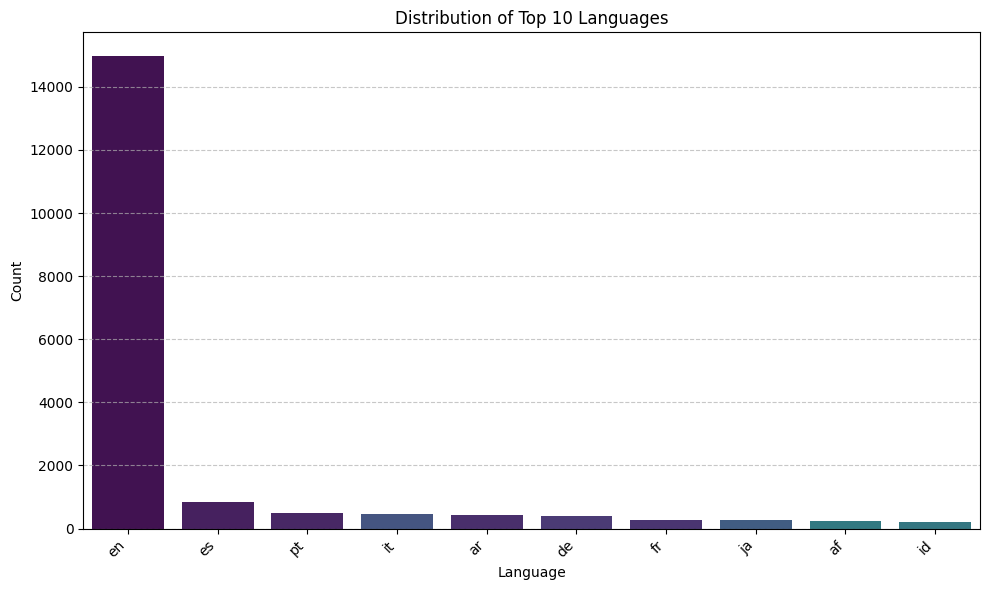

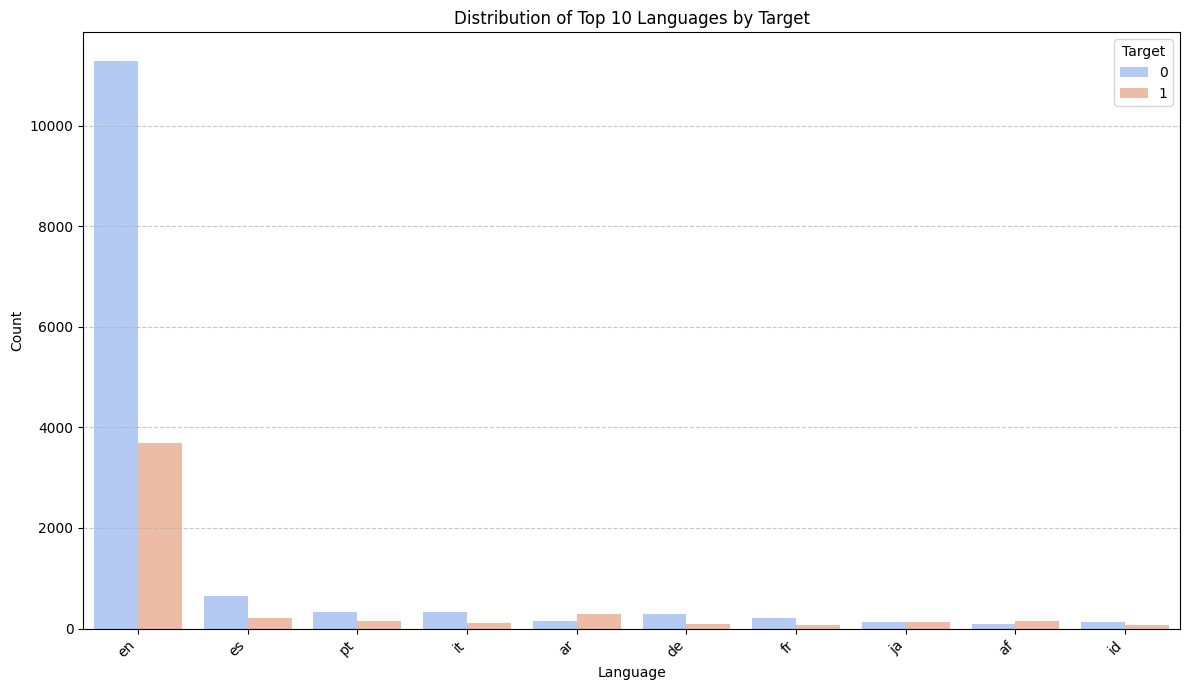

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Analysis of 'lang' ---
print("--- Analysis of 'lang' ---")
print(f"Number of unique languages: {train['lang'].nunique()}")
print("\nValue counts for 'lang':")
print(train['lang'].value_counts())

# Get top N languages for visualization
top_n_languages = 10
top_languages = train['lang'].value_counts().head(top_n_languages).index

print(f"\nTop {top_n_languages} languages and their percentages:")
print(train['lang'].value_counts(normalize=True).head(top_n_languages) * 100)

# Visualize 'lang' distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=train, x='lang', order=top_languages, palette='viridis', hue='lang', legend=False)
plt.title(f'Distribution of Top {top_n_languages} Languages')
plt.xlabel('Language')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Visualize 'lang' distribution by target
plt.figure(figsize=(12, 7))
sns.countplot(data=train, x='lang', hue='target', order=top_languages, palette='coolwarm')
plt.title(f'Distribution of Top {top_n_languages} Languages by Target')
plt.xlabel('Language')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Target')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Keep lang 

### Text and Other

In [ ]:
# location_len - Length of location field
    # Bots often have empty or very short/generic location names
    if 'location' in df.columns:
        location = df['location'].copy()
        location = location.fillna('')  # Fill NaN with empty string
        location_len = location.astype(str).str.len()
        processed_columns.append(location_len.rename('location_len'))
        if verbose:
            print(f"  - location_len: mean={location_len.mean():.2f}, max={location_len.max()}")
    
    # description_len - Length of profile description
    # Bots typically have very short, generic, or missing descriptions
    if 'description' in df.columns:
        description = df['description'].copy()
        description = description.fillna('')  # Fill NaN with empty string
        description_len = description.astype(str).str.len()
        processed_columns.append(description_len.rename('description_len'))
        if verbose:
            print(f"  - description_len: mean={description_len.mean():.2f}, max={description_len.max()}")
    
    # screen_name_len - Length of username/handle
    # Bot usernames often follow patterns (very short, or very long with random characters)
    if 'screen_name' in df.columns:
        screen_name = df['screen_name'].copy()
        screen_name = screen_name.fillna('')  # Fill NaN with empty string
        screen_name_len = screen_name.astype(str).str.len()
        processed_columns.append(screen_name_len.rename('screen_name_len'))
        if verbose:
            print(f"  - screen_name_len: mean={screen_name_len.mean():.2f}, max={screen_name_len.max()}")
    
    # profile_background_image_url_len - Length of background image URL
    # Bots often use default backgrounds (shorter URLs) or no custom backgrounds
    if 'profile_background_image_url' in df.columns:
        bg_image_url = df['profile_background_image_url'].copy()
        bg_image_url = bg_image_url.fillna('')  # Fill NaN with empty string
        profile_background_image_url_len = bg_image_url.astype(str).str.len()
        processed_columns.append(profile_background_image_url_len.rename('profile_background_image_url_len'))
        if verbose:
            print(f"  - profile_background_image_url_len: mean={profile_background_image_url_len.mean():.2f}, max={profile_background_image_url_len.max()}")
    
    # profile_image_url_len - Length of profile image URL
    # Bots often use default profile images (shorter URLs) or follow URL patterns
    if 'profile_image_url' in df.columns:
        profile_image_url = df['profile_image_url'].copy()
        profile_image_url = profile_image_url.fillna('')  # Fill NaN with empty string
        profile_image_url_len = profile_image_url.astype(str).str.len()
        processed_columns.append(profile_image_url_len.rename('profile_image_url_len'))
        if verbose:
            print(f"  - profile_image_url_len: mean={profile_image_url_len.mean():.2f}, max={profile_image_url_len.max()}")
    
    # Additional textual features
    
    # description_has_url - Whether description contains URLs (common in spam bots)
    if 'description' in df.columns:
        description = df['description'].copy()
        description = description.fillna('')
        # Check for common URL patterns
        description_has_url = description.astype(str).str.contains(
            r'http[s]?://|www\.|\.com|\.net|\.org|t\.co', 
            case=False, 
            na=False
        ).astype(int)
        processed_columns.append(description_has_url.rename('description_has_url'))
        if verbose:
            print(f"  - description_has_url: {description_has_url.sum()} accounts have URLs in description ({description_has_url.mean()*100:.1f}%)")
    
    # screen_name_has_numbers - Whether username contains numbers (common bot pattern)
    if 'screen_name' in df.columns:
        screen_name = df['screen_name'].copy()
        screen_name = screen_name.fillna('')
        screen_name_has_numbers = screen_name.astype(str).str.contains(r'\d', na=False).astype(int)
        processed_columns.append(screen_name_has_numbers.rename('screen_name_has_numbers'))
        if verbose:
            print(f"  - screen_name_has_numbers: {screen_name_has_numbers.sum()} accounts have numbers in username ({screen_name_has_numbers.mean()*100:.1f}%)")
    
    # location_is_empty - Whether location field is empty (many bots don't set location)
    if 'location' in df.columns:
        location = df['location'].copy()
        location_is_empty = (location.isnull() | (location.astype(str).str.strip() == '') | (location.astype(str).str.lower() == 'unknown')).astype(int)
        processed_columns.append(location_is_empty.rename('location_is_empty'))
        if verbose:
            print(f"  - location_is_empty: {location_is_empty.sum()} accounts have empty/unknown location ({location_is_empty.mean()*100:.1f}%)")
    
    # description_is_empty - Whether description is empty (many bots have no description)
    if 'description' in df.columns:
        description = df['description'].copy()
        description_is_empty = (description.isnull() | (description.astype(str).str.strip() == '')).astype(int)
        processed_columns.append(description_is_empty.rename('description_is_empty'))
        if verbose:
            print(f"  - description_is_empty: {description_is_empty.sum()} accounts have empty description ({description_is_empty.mean()*100:.1f}%)")
    

## Process Data